# Lab 12: How to answer from documents with retrieval

**Notebook 1 of 2: meet retrieval on the house notes of a flat**

## Goal

Answer questions from documents that were not in the model's training data. We turn each document into a list of numbers (an
**embedding**), find the documents whose numbers are nearest to the question's, and let the model answer only from
those. This notebook uses seven one-line notes that a host leaves for a guest in a flat: where the wifi password is,
when the bins go out, where guests park. A question about parking finds the parking note without sharing a single
word with it. Then the guest asks who has the spare key. The nearest note is about other keys, and with only that
note in the prompt the model says, politely and without any error, that it does not know. With one more note it
answers. Last, a question that no note answers still gets notes back, and we see which step has to refuse.

Notebook 2 does the same at the Chinook music shop's support desk, on the shop's 36 policy and ticket files.

## What you will learn

- How to compare two vectors with cosine similarity, by hand on vectors of two numbers.
- How to turn a text into an embedding with the OpenAI API, and read its shape and its length.
- How to search a handful of texts by meaning with one matrix product, and read the ranking.
- How to store the same texts in Chroma, look inside the collection with `peek()`, and read a raw query result
  before a helper wraps it.
- How to answer only from the retrieved texts, and why a search that keeps too few can hand the model the wrong one.
- Why a search returns texts even when none of them answers, and which step has to refuse.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model names from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


One client for the whole notebook, with a 60-second limit on each request. `models.env` names a second model for
this lab, the **embedding model**: it reads a text and returns numbers, and writes no text at all.

In [2]:
import math
import numpy as np
from openai import OpenAI, omit

client = OpenAI(timeout=60)
EMBEDDING_MODEL = settings["EMBEDDING_MODEL"]
print("embedding model:", EMBEDDING_MODEL)

embedding model: text-embedding-3-small


Every chat call in this notebook passes `reasoning_effort=EFFORT or omit`: `EFFORT` is the setting the first cell
printed, and `omit` leaves the argument out of the request when `models.env` sets no effort.

---

## Part A: Ask the model a question about our flat

A model writes its reply from two things: what it learned in training, and what we put in the request. A guest's
question about one particular flat is in neither. We ask with nothing else in the request.

In [3]:
response = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "What is the wifi password in our flat?"}],
    reasoning_effort=EFFORT or omit,
)
print(response.choices[0].message.content)

I don’t know your flat’s Wi‑Fi password. Check the router label, your ISP’s setup card or app, or ask whoever manages the network.


In our run the model said it does not know the flat's Wi-Fi password, and suggested checking the router's label or asking whoever manages the network. That is the honest reply: nothing in the request holds the password.

### The house notes

Here is what the host wrote down: seven notes, each one line, in a dictionary. The key is a short name for the note,
and the value is its text.

In [4]:
NOTES = {
    "wifi": "The wifi password is on a sticker on the fridge door.",
    "bins": "Bins go out on Tuesday night; the truck comes early on Wednesday.",
    "parking": "Guests park on Hill Street, outside number 12.",
    "boiler": "If the hot water stops, press the red reset button on the boiler.",
    "quiet": "Quiet hours start at 22:00 on weeknights.",
    "neighbours": "Omar and Lina in flat 4 keep a spare key to our flat.",
    "window_keys": "Spare keys for the windows are in the kitchen drawer.",
}

for name, text in NOTES.items():
    print(f"{name:12} {text}")

wifi         The wifi password is on a sticker on the fridge door.
bins         Bins go out on Tuesday night; the truck comes early on Wednesday.
parking      Guests park on Hill Street, outside number 12.
boiler       If the hot water stops, press the red reset button on the boiler.
quiet        Quiet hours start at 22:00 on weeknights.
neighbours   Omar and Lina in flat 4 keep a spare key to our flat.
window_keys  Spare keys for the windows are in the kitchen drawer.


A person reads all seven in a few seconds and knows that the wifi password is on the fridge.

**Why not put every note in every request?** With seven notes we could. A shop with thousands of documents cannot:
every call would carry all of them, the bill grows with every token sent, and most of the text would be about
something else. So for each question we will pick the few notes that matter and send only those. That is
**retrieval**. To pick, the program needs a way to say which note is close in meaning to the question, and words
alone are not enough: a guest who asks *Where do I leave my car?* uses no word of the parking note.

**Checkpoint A.** Without the notes the model cannot give the password (it says it does not know). The seven notes
print, one per line.

---

## Part B: Measure how close two meanings are with cosine similarity

An embedding model turns a text into a list of numbers, a **vector**. Texts with similar meaning get vectors that
point in similar directions. Before we look at a real one, we need a ruler for "point in similar directions", and we
build it on vectors small enough to check in our heads.

### Cosine similarity on vectors of two numbers

Three arrows with two numbers each: `a = [1, 0]` points east, `c = [0, 1]` points north, and `b = [0.8, 0.6]` points
between them, closer to east.

**Cosine similarity** measures the angle between two vectors. It is their **dot product** (multiply the numbers in
the same position, then add) divided by their two lengths:

$$\cos(a, b) = \frac{\sum_i a_i\, b_i}{|a|\;|b|}$$

1 means the same direction, 0 means a right angle (nothing in common). **Bigger is nearer.**

In [5]:
def cosine(a, b):
    dot = sum(x * y for x, y in zip(a, b))
    return dot / (math.sqrt(sum(x * x for x in a)) * math.sqrt(sum(y * y for y in b)))


a, b, c = [1, 0], [0.8, 0.6], [0, 1]
print("a vs b:", round(cosine(a, b), 4))
print("a vs c:", round(cosine(a, c), 4))

a vs b: 0.8
a vs c: 0.0


`zip(a, b)` pairs the numbers in the same position, the first with the first and the second with the second. Check
both lines by hand:

- **a vs b:** the dot product is $1 \times 0.8 + 0 \times 0.6 = 0.8$. Both lengths are 1 ($\sqrt{0.8^2 + 0.6^2} =
  \sqrt{1} = 1$), so there is nothing to divide by: the cosine is **0.8**, close to the same direction.
- **a vs c:** $1 \times 0 + 0 \times 1 = 0$. East and north are at a right angle: cosine **0**.

### One note as an embedding

Now a real embedding of one note. The call is `client.embeddings.create`, a different endpoint from the chat calls:
it returns numbers and writes no text.

In [6]:
response = client.embeddings.create(model=EMBEDDING_MODEL, input=NOTES["parking"])
vector = response.data[0].embedding

print(type(vector).__name__, "of", len(vector), "numbers")
print("first 6:", [round(x, 4) for x in vector[:6]])
print("tokens read:", response.usage.prompt_tokens)

list of 1536 numbers
first 6: [0.0055, -0.0576, 0.0225, -0.0326, -0.0098, -0.0356]
tokens read: 12


Reading the output:

- `response.data` holds one item per text we sent. We sent one, so `data[0]` is ours, and `.embedding` is its
  vector.
- **A list of 1,536 numbers.** One vector for the whole note. A one-line note and a long document both get
  exactly this many numbers, and that fixed length is what makes any two texts comparable.
- **The first six numbers** are small, some positive and some negative. No single number means anything a person
  can read: there is no "parking" position. Only the whole vector, compared with another vector, carries meaning.
- **12 tokens read.** Embeddings are billed by the tokens read, at the embedding price in `models.env`.

### The length of the vector

A vector's length is the square root of the sum of its squared numbers: Pythagoras, in 1,536 dimensions.

In [7]:
length = math.sqrt(sum(x * x for x in vector))
print("length:", round(length, 4))

length: 1.0003


1.0003: the vector has length 1, give or take rounding in the last digits. OpenAI's embedding models return
vectors **of length 1**, so every text becomes a point on the same sphere and only the direction differs.

That makes cosine simple: we divide the dot product by $1 \times 1$. **For these vectors, the dot product is the
cosine.** Part C uses that to compare the question with all seven notes in one line.

**Checkpoint B.** On the small vectors, cosine 0.8 for `a` and `b` and 0 for `a` and `c`. The parking note became a
`list` of 1,536 numbers of length 1.0003.

---

## Part C: Search the notes by meaning

One vector tells us nothing alone. This part embeds all seven notes and the guest's question, and ranks the notes by
their cosine with the question.

`input` also takes a list of texts: one call returns one vector per text, **in the same order**.
`np.array` stacks the seven vectors into a matrix `D`.

In [8]:
names = list(NOTES)
response = client.embeddings.create(model=EMBEDDING_MODEL, input=list(NOTES.values()))
D = np.array([item.embedding for item in response.data])

print("D shape:", D.shape)

D shape: (7, 1536)


`D` has shape **(7, 1536)**:

- **7 rows:** one vector per note. Row `i` belongs to `names[i]`.
- **1,536 columns:** the numbers of each vector.

> **⚠️ Keep vectors and names aligned.** `names` and the texts we sent come from the same dictionary in the same
> order. If one of them were sorted on its own, `D` would keep its shape and the search below would still run, but
> its results would point at the wrong notes.

`D` is a very small **vector store**, a place that keeps vectors so we can search them, held in a Python
variable. Part D replaces it with a real one.

### The question as a vector

The question is embedded with the same model: only vectors from one model can be compared. *Where do I leave my
car?* shares no word with any of the notes.

In [9]:
QUESTION = "Where do I leave my car?"
q = np.array(client.embeddings.create(model=EMBEDDING_MODEL, input=QUESTION).data[0].embedding)
print("question vector:", q.shape)

question vector: (1536,)


### A picture of the eight vectors

We cannot draw 1,536 dimensions. We can draw a shadow of them: the two directions in which our eight vectors
(seven notes and the question) spread out the most. This is called **principal component analysis** (PCA). Three
steps, each one line:

1. `np.vstack` puts the question under the seven notes: a matrix of 8 rows.
2. Subtracting the average row moves the middle of the eight points to zero.
3. `np.linalg.svd` finds the directions of greatest spread, most spread first. `centred @ directions[:2].T` gives
   each point its two coordinates along the first two directions.

`spread` measures how much of the points' spread each direction holds, so we can print the share our picture keeps.

Before you run it: which note will sit nearest the star, the question?

share of the spread in the picture: 40%


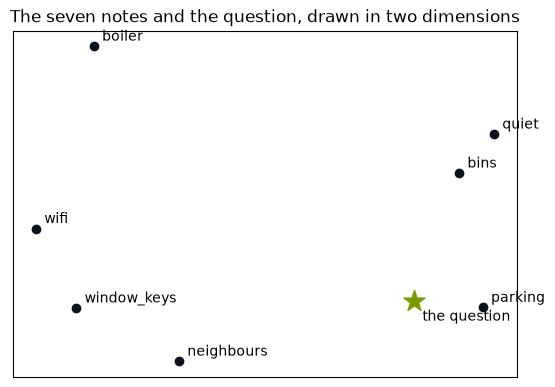

In [10]:
import matplotlib.pyplot as plt

points = np.vstack([D, q])
centred = points - points.mean(axis=0)
_, spread, directions = np.linalg.svd(centred, full_matrices=False)
xy = centred @ directions[:2].T
print(f"share of the spread in the picture: {(spread[:2] ** 2).sum() / (spread ** 2).sum():.0%}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(xy[:7, 0], xy[:7, 1], color="#0B1220")
for (x, y), name in zip(xy[:7], names):
    ax.annotate(name, (x, y), textcoords="offset points", xytext=(6, 4))
ax.scatter(xy[7, 0], xy[7, 1], marker="*", s=250, color="#7A9A00")
ax.annotate("the question", (xy[7, 0], xy[7, 1]), textcoords="offset points", xytext=(6, -14))
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("The seven notes and the question, drawn in two dimensions")
plt.show()

The star sits right beside `parking`, and far from `boiler` and `wifi`. Notice also that `window_keys` and `neighbours` sit close together: both notes are about spare keys. Part F comes back to that pair.

**Important:** the picture keeps 40% of the spread. It is a shadow: two points that look close may be further
apart in the full 1,536 numbers. Use it to see the idea, and the scores for the answer.

### Score every note

`D @ q` multiplies each row of `D` by `q`, number by number, and adds the products: seven dot products, one per
note. Every vector has length 1, so each dot product is a cosine. `np.argsort(-scores)` lists the row positions from
the highest score to the lowest (the minus sign turns "sort from smallest" into "highest first").

In [11]:
scores = D @ q
order = np.argsort(-scores)

for i in order:
    print(f"{scores[i]:.3f}  {names[i]}")

0.379  parking
0.254  bins
0.253  neighbours
0.249  window_keys
0.202  wifi
0.174  quiet
0.098  boiler


`parking` comes first at **0.379**. The next note, `bins`, scores 0.254, and the rest fall to 0.098 (`boiler`).

Notice two things:

- **The parking note shares no word with the question.** "Leave my car" and "guests park on Hill Street" are close in
  meaning, and the embeddings put them close. A search that compared words would have found nothing.
- **Every note gets a score,** the boiler too. A search ranks everything it holds; it has no way to return "nothing here".
  Part G comes back to this.

**Checkpoint C.** `D` is (7, 1536). The picture shows the question next to the parking note, and the scores put
`parking` first at 0.379.

---

## Part D: Store and search the notes in Chroma

Our search works because we keep `D`, `names` and `NOTES` in three variables and keep them in the same order
ourselves. A **vector store** keeps each vector together with its id and its text, and searches them for us; a real
one also finds the nearest vectors quickly among millions and keeps them on disk. **Chroma** is an open-source
vector store. Here it runs inside this Python process.

A **collection** is Chroma's name for one table of records. We create one and add the seven notes as three lists in
the same order: the ids, the texts and the vectors we already have.

In [12]:
import chromadb

chroma = chromadb.EphemeralClient()
collection = chroma.get_or_create_collection("house_notes", configuration={"hnsw": {"space": "cosine"}})
collection.add(ids=names, documents=list(NOTES.values()), embeddings=D.tolist())

print("stored:", collection.count())
print("distance:", collection.configuration["hnsw"]["space"])

stored: 7
distance: cosine


- `EphemeralClient` keeps the collection in this process's memory: restart the kernel and it is gone. Notebook 2
  keeps one on disk.
- `get_or_create_collection` returns the collection if it already exists, so running the cell again does not fail.
  Adding the same ids again changes nothing.
- We passed our own vectors, so Chroma embeds nothing: OpenAI embeds, Chroma stores and ranks. (Given texts with no
  vectors, Chroma would embed them with a small model of its own, which our questions would not match.)
- `"space": "cosine"` asks Chroma to rank by cosine. It reports a **distance**, `1 − cosine`, so **smaller is
  nearer**. Chroma's default is `l2`, the squared straight-line distance; for vectors of length 1 it puts the notes
  in exactly the same order.

### Look inside the collection

`peek()` returns the first few records, with every field Chroma keeps.

In [13]:
collection.peek(2)

{'ids': ['wifi', 'bins'],
 'embeddings': array([[-0.00814056, -0.0305481 , -0.06524658, ..., -0.02490234,
          0.01605225, -0.0266571 ],
        [-0.02835083,  0.00600815, -0.01263428, ...,  0.00575256,
         -0.02613831, -0.01003265]], shape=(2, 1536)),
 'documents': ['The wifi password is on a sticker on the fridge door.',
  'Bins go out on Tuesday night; the truck comes early on Wednesday.'],
 'uris': None,
 'included': ['metadatas', 'documents', 'embeddings'],
 'data': None,
 'metadatas': [None, None]}

Each field is a list with one entry per record, in the same order: `ids` (our names), `embeddings` (numpy shortens
the 1,536 numbers with `...`), `documents` (the texts), and `metadatas` (`None`: we gave no labels; notebook 2
does). `included` names the fields that came back.

### Query the collection directly

We ask the collection for the 3 notes nearest to the question's vector, and print the whole result before picking it
apart. `q.tolist()` turns the numpy vector into a plain list.

In [14]:
got = collection.query(query_embeddings=[q.tolist()], n_results=3)
got

{'ids': [['parking', 'bins', 'neighbours']],
 'embeddings': None,
 'documents': [['Guests park on Hill Street, outside number 12.',
   'Bins go out on Tuesday night; the truck comes early on Wednesday.',
   'Omar and Lina in flat 4 keep a spare key to our flat.']],
 'uris': None,
 'included': ['metadatas', 'documents', 'distances'],
 'data': None,
 'metadatas': [[None, None, None]],
 'distances': [[0.6211727857589722, 0.7463736534118652, 0.7467490434646606]]}

Notice the keys: every field the store can return is there, filled in or `None`.

In [15]:
got.keys()

dict_keys(['ids', 'embeddings', 'documents', 'uris', 'included', 'data', 'metadatas', 'distances'])

What each key holds in this result:

| Key | Here |
|---|---|
| `ids` | the three note names, nearest first |
| `distances` | `1 − cosine` for each, smaller is nearer |
| `documents` | the three texts |
| `metadatas` | `None` for each: no labels |
| `included` | which of the fields were filled in |
| `embeddings` | `None`: vectors are not sent back unless asked for (`include=["embeddings"]`) |
| `uris`, `data` | `None`: for images and other data we do not store |

**Why is every field a list of lists?** `query_embeddings` takes a *list* of questions, so one call can search for
several at once, and the result holds one inner list per question. We sent one question, so `got["ids"][0]` is the
list of ids for our question, and `got["ids"][0][0]` is its nearest note. `zip` pairs the ids and the distances by
position:

In [16]:
for note_id, distance in zip(got["ids"][0], got["distances"][0]):
    print(f"distance {distance:.3f}  cosine {1 - distance:.3f}  {note_id}")

distance 0.621  cosine 0.379  parking
distance 0.746  cosine 0.254  bins
distance 0.747  cosine 0.253  neighbours


The same three notes as in Part C, `parking`, `bins` and `neighbours`, with the same cosines (0.379, 0.254 and 0.253): Chroma ranked the same vectors with the same ruler. Chroma did nothing we could not do ourselves; it keeps the ids, texts and vectors together, so we no longer
have to.

### `search`: a helper that returns the same ids, texts and scores

Every search from here on repeats the same steps: embed the question, query, take the `[0]`. Two small functions do
them. `embed` is the embedding call of Part B, returning only the vector. `search` returns the same ids, texts and
distances as the raw result, as one dictionary per note, with the distance turned back into a cosine.

In [17]:
def embed(text):
    return client.embeddings.create(model=EMBEDDING_MODEL, input=text).data[0].embedding


def search(question, k=3):
    got = collection.query(query_embeddings=[embed(question)], n_results=k)
    rows = []
    for note_id, text, distance in zip(got["ids"][0], got["documents"][0], got["distances"][0]):
        rows.append({"id": note_id, "text": text, "cosine": round(1 - distance, 3)})
    return rows


search(QUESTION)

[{'id': 'parking',
  'text': 'Guests park on Hill Street, outside number 12.',
  'cosine': 0.379},
 {'id': 'bins',
  'text': 'Bins go out on Tuesday night; the truck comes early on Wednesday.',
  'cosine': 0.254},
 {'id': 'neighbours',
  'text': 'Omar and Lina in flat 4 keep a spare key to our flat.',
  'cosine': 0.253}]

The same three notes and cosines as the raw result, now one dictionary per note with its `id`, its `text` and its `cosine`: what the next step, packing the notes into a prompt, needs.

**Checkpoint D.** `stored: 7` and `distance: cosine`; the raw result has the keys `ids`, `embeddings`, `documents`,
`uris`, `included`, `data`, `metadatas` and `distances`, and the filled fields (`ids`, `documents`, `metadatas`, `distances`) each hold one
inner list for our one question; the ids come back in the order of Part C, `parking` first.

---

## Part E: Answer from the notes the search found

We have the first half of the job: find the nearest notes. The second half hands them to the chat model with one
instruction: answer only from these. Here is the whole of it, called **retrieval-augmented generation** (RAG). The
black boxes are model calls; the lime boxes are our code.

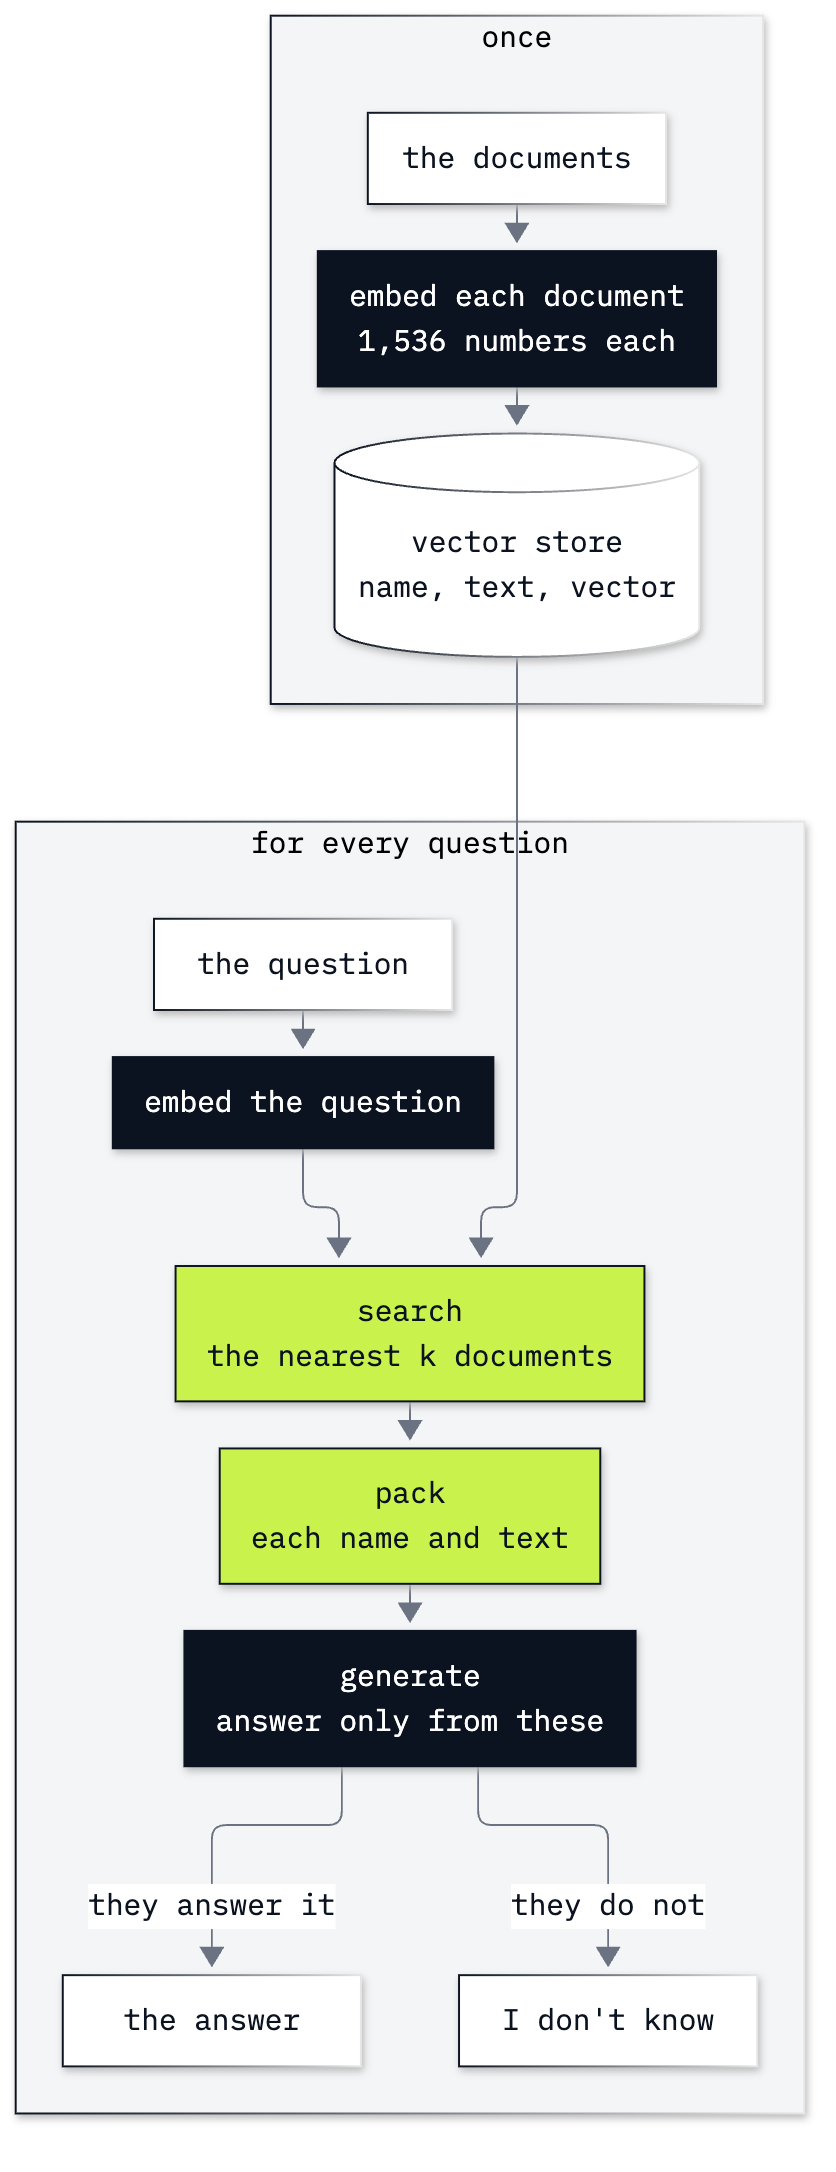

In [18]:
from IPython.display import Image

Image("resources/lab12_retrieve_then_generate.png", width=380)

Read it in two halves. **Once:** every document is embedded and stored with its name (Parts C and D). **For every
question:** embed it, search for the nearest `k`, pack them with their names, and generate an answer from them, or
"I don't know".

### Pack the notes

We search with `k=1`, the nearest note only, and put each note we found under its name in square brackets, so the
model, and anyone checking the reply, can tell which note a fact came from.

In [19]:
found = search(QUESTION, k=1)
packed = "\n".join(f"[{row['id']}] {row['text']}" for row in found)
print(packed)

[parking] Guests park on Hill Street, outside number 12.


Packing keeps the search's order and labels each note. It does not summarise, rewrite or judge the notes.

### Generate the answer

The rules go in the system message: answer only from the notes, and say so when they do not say. The user message
holds the packed notes and the question.

In [20]:
RULES = "Answer only from the notes. If the notes do not say, say you do not know."

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": RULES},
        {"role": "user", "content": f"Notes:\n{packed}\n\nQuestion: {QUESTION}"},
    ],
    reasoning_effort=EFFORT or omit,
)
print(response.choices[0].message.content)
print("prompt tokens:", response.usage.prompt_tokens)

Leave your car on Hill Street, outside number 12.
prompt tokens: 54


In our run: *Leave your car on Hill Street, outside number 12.*, from a prompt of 54 tokens. The model read one note, not seven: that is the point of retrieval.

### `answer()`: one function that searches, packs and generates

`answer()` returns the names of the notes it used beside the reply, because
the reply alone does not say what the model was given.

In [21]:
def answer(question, k):
    found = search(question, k)
    packed = "\n".join(f"[{row['id']}] {row['text']}" for row in found)
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": RULES},
            {"role": "user", "content": f"Notes:\n{packed}\n\nQuestion: {question}"},
        ],
        reasoning_effort=EFFORT or omit,
    )
    return [row["id"] for row in found], response.choices[0].message.content

**Checkpoint E.** The packed prompt holds one line, `[parking] Guests park on Hill Street, outside number 12.`, and
the reply sends the car to Hill Street.

---

## Part F: Ask a question whose nearest note is the wrong one

The guest is locked out: *Who has the spare key?* The notes do say: Omar and Lina in flat 4. First, what does the
search return?

In [22]:
KEY_QUESTION = "Who has the spare key?"

for row in search(KEY_QUESTION, k=3):
    print(row["cosine"], row["id"], "|", row["text"])

0.6 window_keys | Spare keys for the windows are in the kitchen drawer.
0.553 neighbours | Omar and Lina in flat 4 keep a spare key to our flat.
0.27 wifi | The wifi password is on a sticker on the fridge door.


`window_keys` comes first at 0.6, and `neighbours` second at 0.553. Both notes share the words *spare key* with the question, and the embedding still put the window note first; the scores do not tell us why. The search ranks by closeness, and the closest note is not the one that answers.

Before you run it: with `k=1`, only the nearest note goes in the prompt. What will the model say?

In [23]:
used, reply = answer(KEY_QUESTION, k=1)
print("notes used:", used)
print(reply)

notes used: ['window_keys']
I don’t know who has the spare key. The notes only say the spare keys are in the kitchen drawer.


In our run: *I don’t know who has the spare key. The notes only say the spare keys are in the kitchen drawer.* Read the second sentence too: the note says spare keys **for the windows**, and the reply dropped those three words, so it reads as if it were about the guest's key.

Read what happened. The model did what the rules asked: it answered from the one note it was given, and that note
does not say who has the key. For the guest the answer is still wrong, because the notes do say. **Nothing in the
reply shows that the search failed:** no error was raised, and the reply sounds careful. Only the list of notes used
gives it away.

Now the same question with the two nearest notes:

In [24]:
used, reply = answer(KEY_QUESTION, k=2)
print("notes used:", used)
print(reply)

notes used: ['window_keys', 'neighbours']
Omar and Lina in flat 4 have a spare key to your flat.


With the two nearest notes: *Omar and Lina in flat 4 have a spare key to your flat.* The answering note was second, and now it is in the prompt.

A bigger `k` fixed this question, at a price: every request carries more text, and more of it is about something
else. Which `k` is enough depends on the questions; notebook 2 shows the same miss on a shop's files, and the extra
notebook measures it over many questions.

**Checkpoint F.** The search puts `window_keys` first and `neighbours` second. With `k=1` the reply says the notes do
not say who has the key; with `k=2` it names Omar and Lina in flat 4.

---

## Part G: Ask a question that no note answers

*What is the landlord's bank PIN?* None of the notes holds it, and none should. What does the search return?

In [25]:
PIN_QUESTION = "What is the landlord's bank PIN?"

for row in search(PIN_QUESTION, k=3):
    print(row["cosine"], row["id"])

0.318 neighbours
0.265 wifi
0.255 window_keys


Three notes come back: `neighbours` (0.318), `wifi` (0.265) and `window_keys` (0.255). The scores are lower than those of the answering notes in Part C (0.379) and Part F (0.553), but there are still three notes. A search returns the `k` nearest every time; it never returns "nothing found".

Do not read a low score as "nothing here": in Part F the wrong note scored 0.6, higher than the right note in Part C.
A score compares the notes for one question; it does not say whether any of them answers. The extra notebook
tests a cut-off over ten questions.

Now the whole pipeline, with those three notes:

In [26]:
used, reply = answer(PIN_QUESTION, k=3)
print("notes used:", used)
print(reply)

notes used: ['neighbours', 'wifi', 'window_keys']
I don’t know. The notes don’t say.


In our run: *I don’t know. The notes don’t say.*

The search still returned three notes. Nearest is not the same as relevant. __The generate step is what has to
refuse__: the second sentence of `RULES` asks for it, and the model read three notes about other things and said so.
The search cannot do that job, because it only ranks.

**Checkpoint G.** Three notes come back for the PIN question, the best of them with a lower cosine than the answering
notes of Parts C and F; the reply says the notes do not say.

---

## What you can do now

- Compute a cosine similarity by hand, and say why a dot product is the cosine for vectors of length 1 (Part B).
- Embed one text and many, and read a vector's length and a matrix's shape (Parts B and C).
- Search a few texts by meaning with `D @ q` and `np.argsort`, and draw them in two dimensions (Part C).
- Store texts and vectors in a Chroma collection, look inside with `peek()`, and read a raw `query` result with one
  inner list per question (Part D).
- Answer only from the retrieved texts, and print which texts were used, so a miss can be seen (Parts E and F).
- Say why a search returns texts for a question nothing answers, and which step refuses (Part G).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `KeyError: 'EMBEDDING_MODEL'` | `models.env` has no embedding model | add an `EMBEDDING_MODEL` line to `models.env` (the repository's copy has one) and run the first two cells again |
| your scores differ from ours in the third decimal | the same text embedded twice can give slightly different numbers | check the order of the notes, not the last digits |

## Challenge

1. **Ask the locked-out question in other words.** Search *I'm locked out. Who can let me in?* with `k=3`, then
   answer it with `k=1`. Which note comes first now, and does the reply help the guest? This question names no key
   at all: what does that tell you about why the window note came first in Part F?
2. **Add a note to the collection.** Write an eighth note, *Glass bottles go in the green box by the back door.*,
   embed it with `embed`, and add it to `collection` with `add` (an id, a document and an embedding, each in a
   list). Then answer *Where does an empty wine bottle go?* with `k=1`.

**Expected outcome.** 1. *I'm locked out. Who can let me in?* names no key, and the window-keys note still comes first (ours 0.3, with `neighbours` second at 0.275). At `k=1` the reply says it does not know who can let the guest in, and mentions the window keys: the same miss as Part F. 2. After `add` the collection holds 8 notes, and the wine-bottle question puts the new note first (ours 0.555, far above `bins` at 0.213), with the reply *In the green box by the back door.* A worked solution is in `solved/12a_meet_retrieval_solution.ipynb`.

## Resources

- [OpenAI: vector embeddings](https://developers.openai.com/api/docs/guides/embeddings): the embedding models, their
  sizes, and why their vectors have length 1.
- [Chroma: adding data](https://docs.trychroma.com/docs/collections/add-data): `add` with ids, documents and
  embeddings.
- [Chroma: query and get](https://docs.trychroma.com/docs/querying-collections/query-and-get): `query`, its
  `n_results`, and the shape of the result.
- [Chroma: configure a collection](https://docs.trychroma.com/docs/collections/configure): the distance functions
  (`l2`, `cosine`, `ip`).
- [NumPy: `linalg.svd`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html): the decomposition
  behind the picture in Part C.
- [Lewis and others, Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks (2020)](https://arxiv.org/abs/2005.11401):
  the paper that named RAG.